Вспомогательные функции из лекции

In [19]:
import math
def bisection(f, a, b, eps=1e-9, max_iter=200):
    """
    Метод половинного деления с журналом итераций.

    Возвращает: (корень, журнал, статус)
    статус = 'ok' — достигнута точность по длине интервала
    статус = 'f_zero' — f(c) == 0 (точное попадание)
    статус = 'max_iter' — исчерпан лимит итераций
    """

    fa, fb = f(a), f(b)
    if fa * fb > 0:
        raise ValueError(f"Нет смены знака на [{a}, {b}]: f(a)={fa}, f(b)={fb}")

    journal = [] # список словарей — каждая запись = одна итерация

    for k in range(1, max_iter + 1):
        c = (a + b) / 2
        fc = f(c)
        length = b - a
        # записываем всё, что нужно для аудита
        journal.append({"iter": k, "a": a, "b": b, "c": c, "f(c)": fc, "length": length,})

        # условия остановки
        if fc == 0:
            return c, journal, "f_zero"
        if length < eps:
            return c, journal, "ok"

        # обновляем интервал
        if fa * fc < 0:
            b = c
            fb = fc
        else:
            a = c
            fa = fc

    return c, journal, "max_iter"

def print_journal(journal, title=""):
    if title:
        print(f"\n=== {title} ===")
        print(f"{'k':>3} | {'a':>12} | {'b':>12} | {'c':>12} | "
        f"{'f(c)':>14} | {'b-a':>10}")
    print("-" * 80)
    for row in journal:
        print(f"{row['iter']:>3} | {row['a']:>12.6f} | {row['b']:>12.6f} | "
        f"{row['c']:>12.6f} | {row['f(c)']:>14.3e} | "
        f"{row['length']:>10.2e}")



## Задача 1
Дана функция f(x) = x³ − 6x² + 11x − 6

### 1) График на отрезке [0; 4]

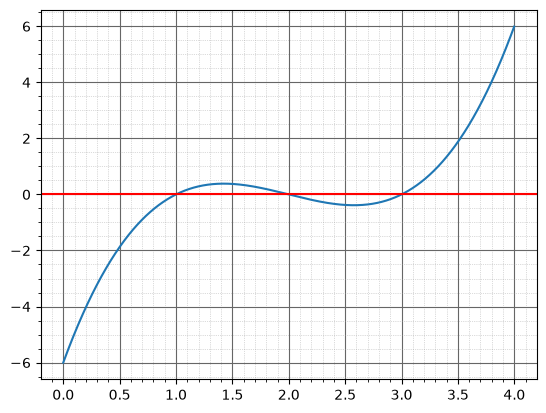

In [20]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(0.0, 4, 0.001)
y = x**3 - 6*x**2 + 11*x - 6

ax = plt.subplot()
ax.minorticks_on() # мелкие деления что бы лучше видеть границы где нахождится корень

ax.plot(x, y)

# 2. Настраиваем сетку для основных (больших) делений
ax.grid(which='major', color='#666666', linestyle='-', linewidth=0.8)

# 3. Настраиваем сетку для вспомогательных (внутренних) делений
ax.grid(which='minor', color='#999999', linestyle=':', linewidth=0.5, alpha=0.7)

# Красная горизонтальная линия на уровне y = 0
ax.axhline(0, color='red', linewidth=1.5)

plt.show()


Для каждого интервала примените bisection с точностью ε = 1e-9
Хоть по графику и видно точные корни, я взял немного кривые интервалы что бы они не находились точно
1) [-0.9; 1.2]
2) [1.8; 2.3]
3) [2.9; 3.2]


In [21]:
f = lambda x: x**3 - 6*x**2 + 11*x - 6

a,b = -0.9, 1.2
x1, j1, s1 = bisection(f, a, b, eps=1e-9)
print_journal(j1, f"f(x) = x³ − 6x² + 11x − 6 [{a}; {b}]")
print(f"корень: {x1:.12f}, f(x1) = {f(x1):.3e}, статус: {s1}")
print(f"итераций: {len(j1)}")

delta = abs(1 -x1)
sigma = delta/1
print(f'Погрешности абсолютная: {delta} относительная: {sigma}')




=== f(x) = x³ − 6x² + 11x − 6 [-0.9; 1.2] ===
  k |            a |            b |            c |           f(c) |        b-a
--------------------------------------------------------------------------------
  1 |    -0.900000 |     1.200000 |     0.150000 |     -4.482e+00 |   2.10e+00
  2 |     0.150000 |     1.200000 |     0.675000 |     -1.001e+00 |   1.05e+00
  3 |     0.675000 |     1.200000 |     0.937500 |     -1.370e-01 |   5.25e-01
  4 |     0.937500 |     1.200000 |     1.068750 |      1.236e-01 |   2.62e-01
  5 |     0.937500 |     1.068750 |     1.003125 |      6.221e-03 |   1.31e-01
  6 |     0.937500 |     1.003125 |     0.970313 |     -6.205e-02 |   6.56e-02
  7 |     0.970313 |     1.003125 |     0.986719 |     -2.709e-02 |   3.28e-02
  8 |     0.986719 |     1.003125 |     0.994922 |     -1.023e-02 |   1.64e-02
  9 |     0.994922 |     1.003125 |     0.999023 |     -1.956e-03 |   8.20e-03
 10 |     0.999023 |     1.003125 |     1.001074 |      2.145e-03 |   4.10e-03
 11

In [22]:
a,b = 1.8, 2.3
x1, j1, s1 = bisection(f, a, b, eps=1e-9)
print_journal(j1, f"f(x) = x³ − 6x² + 11x − 6 [{a}; {b}]")
print(f"корень: {x1:.12f}, f(x1) = {f(x1):.3e}, статус: {s1}")
print(f"итераций: {len(j1)}")
delta = abs(2 -x1)
sigma = delta/2
print(f'Погрешности абсолютная: {delta} относительная: {sigma}')




=== f(x) = x³ − 6x² + 11x − 6 [1.8; 2.3] ===
  k |            a |            b |            c |           f(c) |        b-a
--------------------------------------------------------------------------------
  1 |     1.800000 |     2.300000 |     2.050000 |     -4.988e-02 |   5.00e-01
  2 |     1.800000 |     2.050000 |     1.925000 |      7.458e-02 |   2.50e-01
  3 |     1.925000 |     2.050000 |     1.987500 |      1.250e-02 |   1.25e-01
  4 |     1.987500 |     2.050000 |     2.018750 |     -1.874e-02 |   6.25e-02
  5 |     1.987500 |     2.018750 |     2.003125 |     -3.125e-03 |   3.12e-02
  6 |     1.987500 |     2.003125 |     1.995312 |      4.687e-03 |   1.56e-02
  7 |     1.995312 |     2.003125 |     1.999219 |      7.812e-04 |   7.81e-03
  8 |     1.999219 |     2.003125 |     2.001172 |     -1.172e-03 |   3.91e-03
  9 |     1.999219 |     2.001172 |     2.000195 |     -1.953e-04 |   1.95e-03
 10 |     1.999219 |     2.000195 |     1.999707 |      2.930e-04 |   9.77e-04
 11 

In [23]:
a,b = 2.9, 3.2
x1, j1, s1 = bisection(f, a, b, eps=1e-9)
print_journal(j1, f"f(x) = x³ − 6x² + 11x − 6 [{a}; {b}]")
print(f"корень: {x1:.12f}, f(x1) = {f(x1):.3e}, статус: {s1}")
print(f"итераций: {len(j1)}")

delta = abs(3 -x1)
sigma = delta/3
print(f'Погрешности абсолютная: {delta} относительная: {sigma}')



=== f(x) = x³ − 6x² + 11x − 6 [2.9; 3.2] ===
  k |            a |            b |            c |           f(c) |        b-a
--------------------------------------------------------------------------------
  1 |     2.900000 |     3.200000 |     3.050000 |      1.076e-01 |   3.00e-01
  2 |     2.900000 |     3.050000 |     2.975000 |     -4.814e-02 |   1.50e-01
  3 |     2.975000 |     3.050000 |     3.012500 |      2.547e-02 |   7.50e-02
  4 |     2.975000 |     3.012500 |     2.993750 |     -1.238e-02 |   3.75e-02
  5 |     2.993750 |     3.012500 |     3.003125 |      6.279e-03 |   1.88e-02
  6 |     2.993750 |     3.003125 |     2.998437 |     -3.118e-03 |   9.38e-03
  7 |     2.998437 |     3.003125 |     3.000781 |      1.564e-03 |   4.69e-03
  8 |     2.998437 |     3.000781 |     2.999609 |     -7.808e-04 |   2.34e-03
  9 |     2.999609 |     3.000781 |     3.000195 |      3.907e-04 |   1.17e-03
 10 |     2.999609 |     3.000195 |     2.999902 |     -1.953e-04 |   5.86e-04
 11 

## Вывод
Число итераций примерно соответсвует log2(Δ / ε) в идеале должно быть 29, у меня получилось 30   (math.log2(0.3/1e-9)=28.16)


## Задача 2. Бисекция для уравнения с параметром

Условие. Рассмотрите уравнение f(x) = cos x − kx = 0, где k > 0 — параметр. Это
уравнение возникает в задачах о равновесии маятника с трением.

### 1. Для k = 0.5 локализуйте корень на отрезке [0, 2] (проверьте смену знака).


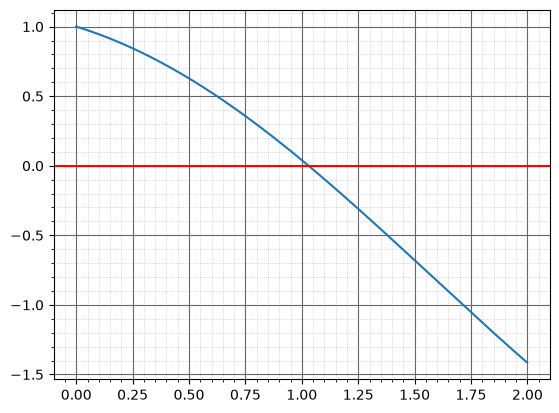

In [24]:
def f(x):
    return np.cos(x) - k*x

k = 0.5
x = np.arange(0,2,0.001)
y = f(x)

ax = plt.subplot()
ax.minorticks_on() # мелкие деления что бы лучше видеть границы где нахождится корень

ax.plot(x, y)

# 2. Настраиваем сетку для основных (больших) делений
ax.grid(which='major', color='#666666', linestyle='-', linewidth=0.8)

# 3. Настраиваем сетку для вспомогательных (внутренних) делений
ax.grid(which='minor', color='#999999', linestyle=':', linewidth=0.5, alpha=0.7)

# Красная горизонтальная линия на уровне y = 0
ax.axhline(0, color='red', linewidth=1.5)

plt.show()

По графику видно что корень находится между 1.00 и 1.05

Примените бисекцию с ε = 10−9, выведите журнал.


In [ ]:
a,b = 0, 2
x1, j1, s1 = bisection(f, a, b, eps=1e-9)
print_journal(j1, f"cos x - {k}x [{a}; {b}]")
print(f"корень: {x1:.12f}, f(x1) = {f(x1):.3e}, статус: {s1}")
print(f"итераций: {len(j1)}")



=== cos x - 0.5x [0; 2] ===
  k |            a |            b |            c |           f(c) |        b-a
--------------------------------------------------------------------------------
  1 |     0.000000 |     2.000000 |     1.000000 |      4.030e-02 |   2.00e+00
  2 |     1.000000 |     2.000000 |     1.500000 |     -6.793e-01 |   1.00e+00
  3 |     1.000000 |     1.500000 |     1.250000 |     -3.097e-01 |   5.00e-01
  4 |     1.000000 |     1.250000 |     1.125000 |     -1.313e-01 |   2.50e-01
  5 |     1.000000 |     1.125000 |     1.062500 |     -4.456e-02 |   1.25e-01
  6 |     1.000000 |     1.062500 |     1.031250 |     -1.878e-03 |   6.25e-02
  7 |     1.000000 |     1.031250 |     1.015625 |      1.928e-02 |   3.12e-02
  8 |     1.015625 |     1.031250 |     1.023438 |      8.715e-03 |   1.56e-02
  9 |     1.023438 |     1.031250 |     1.027344 |      3.422e-03 |   7.81e-03
 10 |     1.027344 |     1.031250 |     1.029297 |      7.731e-04 |   3.91e-03
 11 |     1.029297 | 

### 2. Для k = 1, 2, 5 повторите процедуру. Постройте таблицу: k → корень → число итераций → |f(корень)|

In [26]:
print(f'| k | {"корень":>14} | {"итераций":>10} | {"f(корень)":>14} |')
print(f'|---|-{"-"*14}-|-{"-"*10}-|-{"-"*14}-|')
for k in (1, 2, 5):
    x1, j1, _ = bisection(f, a, b, eps=1e-9)
    print(f'| {k:1} | {x1:14g} | {len(j1):10} | {f(x1):14g} |')

| k |         корень |   итераций |      f(корень) |
|---|----------------|------------|----------------|
| 1 |       0.739085 |         32 |   -7.32998e-10 |
| 2 |       0.450184 |         32 |    9.67629e-10 |
| 5 |       0.196164 |         32 |   -2.00162e-09 |


Как и видно число итераций не зависит от корня (мы можем случайно только на него попасть), а зависит только от длины отрезка и требуемой точности.

### 3. Постройте график зависимости корня от k (для k от 0.1 до 10 с шагом 0.1). 

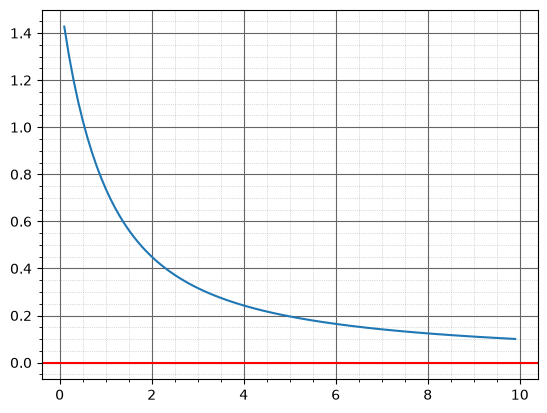

In [27]:
x = np.arange(0.1, 10, 0.1)
y = np.zeros((len(x),), np.float64)

for i, k in enumerate(x):
    x1, _, _ = bisection(f, a, b, eps=1e-9)
    y[i] = x1

ax = plt.subplot()
ax.minorticks_on() # мелкие деления что бы лучше видеть границы где нахождится корень

ax.plot(x, y)

# 2. Настраиваем сетку для основных (больших) делений
ax.grid(which='major', color='#666666', linestyle='-', linewidth=0.8)

# 3. Настраиваем сетку для вспомогательных (внутренних) делений
ax.grid(which='minor', color='#999999', linestyle=':', linewidth=0.5, alpha=0.7)

# Красная горизонтальная линия на уровне y = 0
ax.axhline(0, color='red', linewidth=1.5)

plt.show()

> Как ведёт себя корень при k → 0?

Как видно график - похож на гиперболу.

Геометрически корни уравнения cos(x) = kx — это точки пересечения косинусоиды y = cos(x) и прямой y = kx
при малых k первый корень стремится к pi/2, но т.к. прямая становится почти горизонтальной последний корень -> к бесконечности

> При k → ∞? 
При больших k (например, k = 10) прямая идёт очень круто вверх и пересекает косинусоиду только один раз вблизи нуля.

Получается первый корень лежит на промежутке от 0 до pi/2.


### 4. Для k = 0.5 измените точность

ε: 10−3, 10−6, 10−9, 10−12. Постройте таблицу: ε → число итераций → фактическая ошибка |x − x*|. 
Сравните с теоретической оценкой n ≥ log2(Δ0 / ε).


In [32]:
k = 0.5
print(f'| {"ε ":>14} | {"итераций":>10} | {"оценка ит.":>10} | {"|x − x*|":>14} |')
print(f'|-{"-"*14}-|-{"-"*10}-|-{"-"*10}-|-{"-"*14}-|')
for e in (1e-3, 1e-6, 1e-9, 1e-12):
    x1, j1, _ = bisection(f, a, b, eps=e)
    n = math.ceil(math.log2((b-a)/e))
    print(f'| {e:14g} | {len(j1):10} | {n:10} | {abs(x1-1):14g} |')
    

|             ε  |   итераций | оценка ит. |       |x − x*| |
|----------------|------------|------------|----------------|
|          0.001 |         12 |         11 |      0.0297852 |
|          1e-06 |         22 |         21 |      0.0298667 |
|          1e-09 |         32 |         31 |      0.0298665 |
|          1e-12 |         42 |         41 |      0.0298665 |


Проверьте, что происходит при k = 0: уравнение cos x = 0



In [33]:
k = 0
a,b = 0, 2
x1, j1, s1 = bisection(f, a, b, eps=1e-9)
print_journal(j1, f"cos x - {k}x [{a}; {b}]")
print(f"корень: {x1:.12f}, f(x1) = {f(x1):.3e}, статус: {s1}")
print(f"итераций: {len(j1)}")



=== cos x - 0x [0; 2] ===
  k |            a |            b |            c |           f(c) |        b-a
--------------------------------------------------------------------------------
  1 |     0.000000 |     2.000000 |     1.000000 |      5.403e-01 |   2.00e+00
  2 |     1.000000 |     2.000000 |     1.500000 |      7.074e-02 |   1.00e+00
  3 |     1.500000 |     2.000000 |     1.750000 |     -1.782e-01 |   5.00e-01
  4 |     1.500000 |     1.750000 |     1.625000 |     -5.418e-02 |   2.50e-01
  5 |     1.500000 |     1.625000 |     1.562500 |      8.296e-03 |   1.25e-01
  6 |     1.562500 |     1.625000 |     1.593750 |     -2.295e-02 |   6.25e-02
  7 |     1.562500 |     1.593750 |     1.578125 |     -7.329e-03 |   3.12e-02
  8 |     1.562500 |     1.578125 |     1.570312 |      4.838e-04 |   1.56e-02
  9 |     1.570312 |     1.578125 |     1.574219 |     -3.422e-03 |   7.81e-03
 10 |     1.570312 |     1.574219 |     1.572266 |     -1.469e-03 |   3.91e-03
 11 |     1.570312 |   

На отрезке 0 - 2 бисекция работает хорошо. На этом участке занки функции разные, да и корень только один.
Количество шагов тоже не поменялось. Ничего менять не надо.